# 02 · Intervals and transfer to Facebook and Instagram

Facebook and Instagram have no views, so a model for them can only be **transferred** from platforms that have them. Two checks, with the honest limit that the real answer on Facebook and Instagram is unknown:
1. **Intervals:** do 90% conformal intervals cover about 90% of true values (within a platform, brand-grouped)?
2. **Transfer:** train on two platforms with views, test on the third (leave-one-platform-out). Only features present everywhere are used: likes and comments.

Code: `src/validation.py`, `src/transfer.py`.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu
import transfer as tf
import modeling as mo
import validation as va

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.2f}".format); pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None); pd.set_option("display.max_colwidth", 90)

In [2]:
d = tf.load(ROOT)
d.groupby('platform').y.count().rename(eu.NAMES).to_frame('mentions with views')

,mentions with views
platform,
Facebook,0
Instagram,0
TikTok,2491
X (Twitter),1803
YouTube,2441


## 1 · Do the intervals hold? (within platform, brand-grouped CV)

In [3]:
f, meta = mo.load_features(ROOT)
rows = []
for p in mo.PLATS:
    m = (meta.platform == p).values; X, y, g = f[m].reset_index(drop=True), meta.y[m].reset_index(drop=True), meta.brand[m].reset_index(drop=True)
    pred, lo, hi = va.conformal_cv(mo.hgb, X[[c for gr in mo.GROUPS.values() for c in gr]], y, g)
    cov, width = va.coverage(y.values, lo, hi)
    mae, a, b = va.mae_ci((y - pred).values, g.values)
    rows.append({"platform": eu.NAMES[p], "MAE": mae, "coverage of 90% interval": cov, "mean interval width (log10)": width, "width as a factor": 10 ** width})
pd.DataFrame(rows).set_index("platform").round(2)

,MAE,coverage of 90% interval,mean interval width (log10),width as a factor
platform,,,,
TikTok,0.29,0.89,1.21,16.32
YouTube,0.47,0.90,2.02,103.55
X (Twitter),0.51,0.90,2.12,132.87


## 2 · Leave-one-platform-out transfer

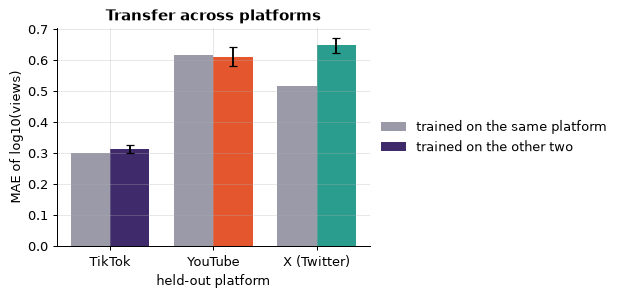

,transfer MAE,CI low,CI high,bias (mean error),in-platform MAE,rows
held-out platform,,,,,,
TikTok,0.31,0.30,0.33,0.03,0.30,2491
YouTube,0.61,0.58,0.64,0.21,0.62,2441
X (Twitter),0.65,0.62,0.67,-0.40,0.52,1803


In [4]:
tab, resid = tf.lopo(d, 'log-log regression')
tf.plot_transfer(tab)
tab.round(2)

In [5]:
tab_g, resid_g = tf.lopo(d, 'gradient model')
tab_g.round(2)

,transfer MAE,CI low,CI high,bias (mean error),in-platform MAE,rows
held-out platform,,,,,,
TikTok,0.35,0.34,0.36,0.01,0.30,2491
YouTube,0.64,0.61,0.68,0.19,0.58,2441
X (Twitter),0.73,0.70,0.75,-0.48,0.52,1803


Interval from other platforms' transfer errors, checked on the held-out platform:

In [6]:
tf.cross_platform_intervals(resid)

,half-width (log10),coverage,target
held-out platform,,,
TikTok,1.38,0.99,0.90
YouTube,1.04,0.82,0.90
X (Twitter),1.05,0.82,0.90


## 3 · Estimate for Facebook and Instagram (cannot be verified)

90% half-width from pooled transfer errors: 1.14 log10 (factor 13.9 each way)


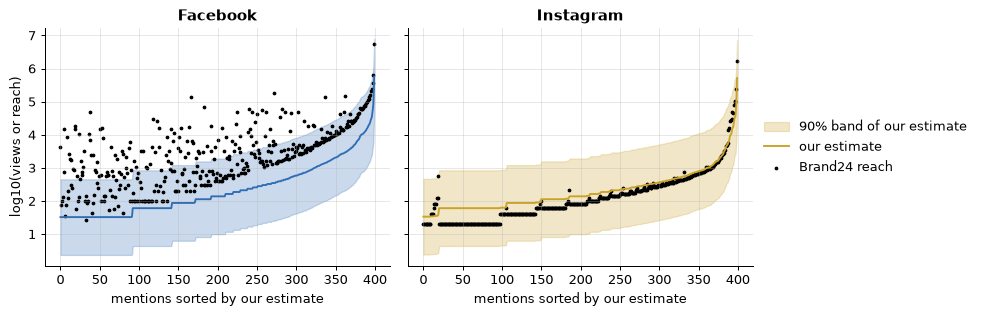

,mentions,median_estimate,median_brand24,median_diff,brand24_inside_band
platform,,,,,
Facebook,2278,2.14,3.46,0.89,0.61
Instagram,1415,2.14,1.90,-0.19,1.00


In [7]:
out, q = tf.predict_unknown(d, 'log-log regression', resid)
print(f"90% half-width from pooled transfer errors: {q:.2f} log10 (factor {10**q:.1f} each way)")
tf.plot_unknown(out)
s = out[out.b24.notna()].assign(inside=lambda x: (x.b24 >= x.lo) & (x.b24 <= x.hi), diff=lambda x: x.b24 - x.pred)
s.groupby('platform').agg(mentions=('pred', 'size'), median_estimate=('pred', 'median'), median_brand24=('b24', 'median'), median_diff=('diff', 'median'), brand24_inside_band=('inside', 'mean')).rename(index=eu.NAMES).round(2)

## Takeaways

- **Intervals are calibrated but wide.** Within a platform the 90% conformal interval covers 89-90% of true values, as it should. The price is width: a factor of about 16 on TikTok, 100 on YouTube and 130 on X (total width, i.e. roughly ×4 / ×10 / ×11 each way).
- **A model trained on other platforms transfers surprisingly well on TikTok and YouTube.** Using only likes and comments, MAE on the held-out platform is 0.31 (TikTok) and 0.61 (YouTube), about the same as training on the platform itself (0.30 / 0.62). On X it is worse (0.65 vs 0.52) with a clear bias of -0.40: the model over-predicts X views, so engagement means something different there.
- **Intervals built from other platforms are not reliably calibrated.** Their coverage on the held-out platform is 99% (TikTok), 82% (YouTube) and 82% (X) against a 90% target. Any interval we give for Facebook and Instagram should be read as optimistic.
- **Facebook and Instagram: an estimate, not a result.** The pooled 90% band is about ×14 each way. On Facebook our median estimate is 2.14 log10 against Brand24's 3.46 (Brand24 about 20 times higher; only 61% of Brand24 values fall inside our band). On Instagram the medians are close (2.14 vs 1.90) and all Brand24 values fall inside the very wide band, which says little. Facebook likes are reactions and Instagram has many zero reaches, so the likes-to-views link may differ from the three platforms we trained on.
- **What we can claim:** engagement is a better basis for reach than followers on the platforms where it can be checked, and the Facebook rule looks high relative to engagement. What we cannot claim: that our numbers or Brand24's are right on Facebook or Instagram, because no ground truth exists there.